# SMA Crossover Backtest — S&P 500

This notebook backtests a simple **moving-average crossover** strategy on the S&P 500 index (`^GSPC`) from 2020 onwards.

**Strategy idea**
- Compute a *fast* (7-day) and a *slow* (14-day) simple moving average (SMA) of the closing price.
- When the fast SMA is **above** the slow SMA the trend is considered up → go **long**.
- When the fast SMA is **below** the slow SMA → go **short** (or sit in cash, in the long/cash variant).

**Notebook outline**
1. Setup & data download
2. Indicators (SMAs) and trading signal
3. Positions and returns (with transaction costs)
4. Equity curves vs. buy-and-hold benchmark
5. Performance metrics — Sharpe ratio & maximum drawdown
6. Parameter sweep over different SMA windows

## 1. Setup

In [72]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

## 2. Download price data

Daily OHLCV data for the S&P 500 index from Yahoo Finance.
`multi_level_index=False` gives flat column names (`Close`, `High`, …) instead of a `(field, ticker)` MultiIndex.

In [73]:
TICKER = "^GSPC"
START = "2020-01-01"

data = yf.download(TICKER, start=START, multi_level_index=False)
data

[*********************100%***********************]  1 of 1 completed


,Close,High,Low,Open,Volume
Date,,,,,
2020-01-02,3257.850098,3258.139893,3235.530029,3244.669922,3459930000
2020-01-03,3234.850098,3246.149902,3222.340088,3226.360107,3484700000
2020-01-06,3246.280029,3246.840088,3214.639893,3217.550049,3702460000
2020-01-07,3237.179932,3244.909912,3232.429932,3241.860107,3435910000
2020-01-08,3253.050049,3267.070068,3236.669922,3238.590088,3726840000
...,...,...,...,...,...
2026-10-01,7666.450195,7684.750000,7616.779785,7666.470215,5783800000
2026-10-02,7722.720215,7754.669922,7700.509766,7726.240234,5277430000
2026-10-05,7773.950195,7794.350098,7727.589844,7730.859863,5840900000


Only the closing price is needed for this strategy. `.copy()` makes `data` an independent DataFrame so adding columns later doesn't raise a `SettingWithCopyWarning`.

In [74]:
data = data[['Close']].copy()
data

,Close
Date,
2020-01-02,3257.850098
2020-01-03,3234.850098
2020-01-06,3246.280029
2020-01-07,3237.179932
2020-01-08,3253.050049
...,...
2026-10-01,7666.450195
2026-10-02,7722.720215
2026-10-05,7773.950195


## 3. Indicators — simple moving averages

- **7_SMA** — fast average, reacts quickly to price changes.
- **14_SMA** — slow average, smoother trend.

The first 13 rows have no 14-day SMA yet (not enough history), so they are dropped.

In [75]:
FAST, SLOW = 7, 14

data['7_SMA'] = data['Close'].rolling(FAST).mean()
data['14_SMA'] = data['Close'].rolling(SLOW).mean()

In [76]:
# Remove warm-up rows where the slow SMA is not yet defined
data.dropna(subset=['14_SMA'], inplace=True)
data

,Close,7_SMA,14_SMA
Date,,,
2020-01-22,3321.750000,3307.077148,3279.914307
2020-01-23,3325.540039,3312.421456,3284.749302
2020-01-24,3295.469971,3314.181466,3289.079293
2020-01-27,3243.629883,3307.658587,3288.889997
2020-01-28,3276.239990,3301.862863,3291.680001
...,...,...,...
2026-10-01,7666.450195,7689.441406,7671.514997
2026-10-02,7722.720215,7691.825753,7678.853585
2026-10-05,7773.950195,7701.800084,7692.297886


## 4. Trading signal and position

**Signal** (computed at today's close): `1` if fast SMA > slow SMA, else `0`.

**Position** (held during the *next* day):
- `.shift(1)` — we can only act on a signal *after* it is known, so today's signal sets tomorrow's position. This avoids **look-ahead bias**.
- `.replace(0, -1)` — a `0` signal becomes a **short** position (`-1`), so the strategy is always either long (`+1`) or short (`-1`).

In [77]:
data['Signal'] = (data['7_SMA'] > data['14_SMA']).astype(int)
data

,Close,7_SMA,14_SMA,Signal
Date,,,,
2020-01-22,3321.750000,3307.077148,3279.914307,1
2020-01-23,3325.540039,3312.421456,3284.749302,1
2020-01-24,3295.469971,3314.181466,3289.079293,1
2020-01-27,3243.629883,3307.658587,3288.889997,1
2020-01-28,3276.239990,3301.862863,3291.680001,1
...,...,...,...,...
2026-10-01,7666.450195,7689.441406,7671.514997,1
2026-10-02,7722.720215,7691.825753,7678.853585,1
2026-10-05,7773.950195,7701.800084,7692.297886,1


In [78]:
data['Position'] = data['Signal'].shift(1).replace(0, -1)
data

,Close,7_SMA,14_SMA,Signal,Position
Date,,,,,
2020-01-22,3321.750000,3307.077148,3279.914307,1,NaN
2020-01-23,3325.540039,3312.421456,3284.749302,1,1.0
2020-01-24,3295.469971,3314.181466,3289.079293,1,1.0
2020-01-27,3243.629883,3307.658587,3288.889997,1,1.0
2020-01-28,3276.239990,3301.862863,3291.680001,1,1.0
...,...,...,...,...,...
2026-10-01,7666.450195,7689.441406,7671.514997,1,1.0
2026-10-02,7722.720215,7691.825753,7678.853585,1,1.0
2026-10-05,7773.950195,7701.800084,7692.297886,1,1.0


Daily percentage return of the index (buy-and-hold return for each day).

In [79]:
data['Returns'] = data['Close'].pct_change()
data

,Close,7_SMA,14_SMA,Signal,Position,Returns
Date,,,,,,
2020-01-22,3321.750000,3307.077148,3279.914307,1,NaN,NaN
2020-01-23,3325.540039,3312.421456,3284.749302,1,1.0,0.001141
2020-01-24,3295.469971,3314.181466,3289.079293,1,1.0,-0.009042
2020-01-27,3243.629883,3307.658587,3288.889997,1,1.0,-0.015731
2020-01-28,3276.239990,3301.862863,3291.680001,1,1.0,0.010054
...,...,...,...,...,...,...
2026-10-01,7666.450195,7689.441406,7671.514997,1,1.0,0.001949
2026-10-02,7722.720215,7691.825753,7678.853585,1,1.0,0.007340
2026-10-05,7773.950195,7701.800084,7692.297886,1,1.0,0.006634


## 5. Strategy returns and transaction costs

Two variants are compared:

| Column | Description |
|---|---|
| `Strategy_Returns` | **Long/short** — earns `+Returns` when long, `-Returns` when short |
| `Long_cash_returns` | **Long/cash** — long when the signal is up, otherwise flat in cash (0 return) |

**Transaction costs:** `trades = |Δ Position|` — this is `0` when the position is unchanged and `2` when flipping between long (+1) and short (−1), i.e. one trade to close + one to open. Each unit is charged `cost` (0.05%).

> ⚠️ For the long/cash variant, the same `trades` series is used, so each switch is charged 2 × cost even though going long ↔ cash is only a single trade. Costs for that variant are therefore slightly overstated (conservative).

In [80]:
data = data.dropna()

# Gross returns
data['Strategy_Returns'] = data['Position'] * data['Returns']                    # long/short
data['Long_cash_returns'] = data['Position'].replace(-1, 0) * data['Returns']    # long/cash

# Transaction costs
cost = 0.0005                                   # 0.05% per trade, a reasonable ETF estimate
trades = data['Position'].diff().abs()          # 0 = hold, 2 = flip long <-> short

# Net returns after costs
data['Strategy_Net'] = data['Strategy_Returns'] - trades * cost
data['Long_cash_net'] = data['Long_cash_returns'] - trades * cost

## 6. Equity curves

Compounding daily returns with `(1 + r).cumprod()` gives the growth of 1 unit of capital.
Multiplying by `balance` scales it to a $1,000,000 starting account.

- **Equity_Curve** — long/short SMA strategy (net of costs)
- **Long_Cash_EQ** — long/cash SMA strategy (net of costs)
- **Benchmark** — simple buy-and-hold of the S&P 500

In [81]:
balance = 1_000_000   # starting capital in $

data['Equity_Curve'] = (1 + data['Strategy_Net']).cumprod()
data['Long_Cash_EQ'] = (1 + data['Long_cash_net']).cumprod()
data['Benchmark'] = (1 + data['Returns']).cumprod()
data.dropna(inplace=True)   # first row has NaN cost (no previous position to diff against)

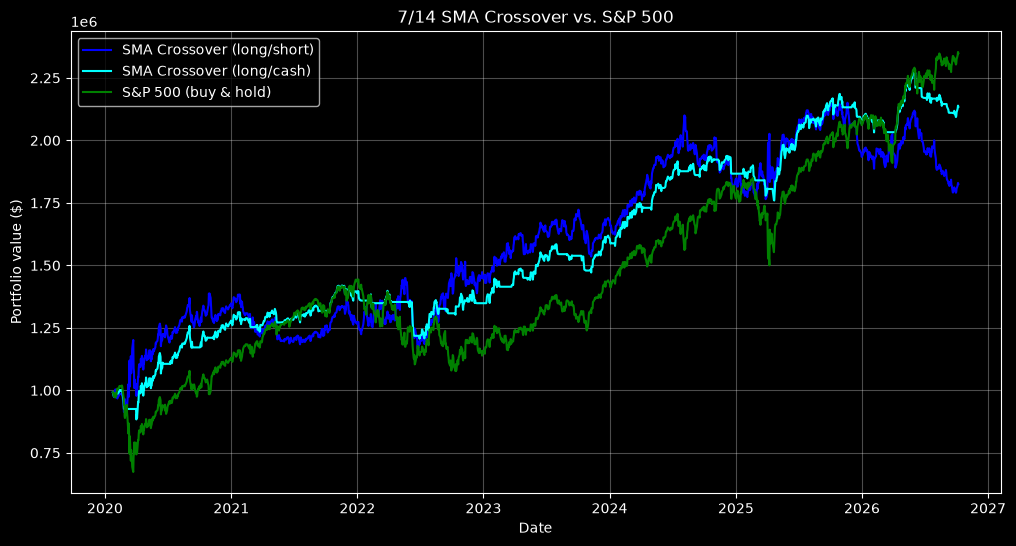

In [82]:
plt.figure(figsize=(12, 6))
plt.plot(data.index, data['Equity_Curve'] * balance, label='SMA Crossover (long/short)', color='blue')
plt.plot(data.index, data['Long_Cash_EQ'] * balance, label='SMA Crossover (long/cash)', color='cyan')
plt.plot(data.index, data['Benchmark'] * balance, label='S&P 500 (buy & hold)', color='green')
plt.title(f'{FAST}/{SLOW} SMA Crossover vs. S&P 500')
plt.xlabel('Date')
plt.ylabel('Portfolio value ($)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 7. Performance metrics

### Sharpe ratio
Annualised risk-adjusted return:

$$\text{Sharpe} = \frac{\text{mean daily return} \times 252}{\text{std of daily returns} \times \sqrt{252}}$$

252 ≈ number of trading days per year. The risk-free rate is assumed to be 0 here.

In [83]:
annual_return = np.mean(data['Strategy_Net']) * 252
annual_vol = np.std(data['Strategy_Net']) * np.sqrt(252)
print(f'Sharpe: {(annual_return / annual_vol).round(2)}')

Sharpe: 0.55


### Maximum drawdown
The largest peak-to-trough decline of the equity curve — "how much would I have lost at worst from a previous high?"

- `cummax()` tracks the running peak of the equity curve.
- Drawdown on each day = (peak − current) / peak.

In [84]:
running_peak = data['Equity_Curve'].cummax()
drawdown = (running_peak - data['Equity_Curve']) / running_peak
print(f'Maximum drawdown: {(drawdown.max() * 100).round(2)}%')

Maximum drawdown: 19.43%


## 8. Parameter sweep — which SMA windows work best?

Tests every (fast, slow) combination where fast < slow and reports the annualised Sharpe ratio, sorted best first.

> **Notes — this sweep differs from the main backtest above:**
> - It is **long/cash** (signal 0 → return 0), not long/short.
> - It ignores **transaction costs**.
> - Rolling windows are recomputed on `data`, which already had its warm-up rows dropped, so longer windows (e.g. 100) lose additional days at the start.
> - Picking the best pair on the same data it was tested on is **in-sample optimisation** → results are likely overfit. Validate on an out-of-sample period before trusting them.

In [85]:
results = {}
for fast in [5, 7, 10, 20]:
    for slow in [14, 30, 50, 100]:
        if fast >= slow:
            continue
        sig = (data['Close'].rolling(fast).mean() > data['Close'].rolling(slow).mean()).astype(int)
        r = data['Close'].pct_change() * sig.shift(1)        # long/cash, no costs
        results[(fast, slow)] = r.mean() / r.std() * np.sqrt(252)

pd.Series(results, name='Sharpe').rename_axis(['fast', 'slow']).sort_values(ascending=False)

fast  slow
7     14      1.158876
      100     1.072802
5     100     0.961299
      14      0.959906
10    100     0.954249
      14      0.886420
      50      0.866287
7     30      0.859387
20    100     0.846692
7     50      0.839469
10    30      0.811448
5     30      0.775740
      50      0.765723
20    30      0.739057
      50      0.706912
Name: Sharpe, dtype: float64